<h1>Lab processing graphs with NetworkX<h1>
The lab was done by Yatsenko Mariana K-13
<h2>Variant 99<h2>
build graph with 10 nodes,11 edges,4 connected components

In [11]:
import networkx as nx
import matplotlib.pyplot as plt

<h3>Graph construction<h3>

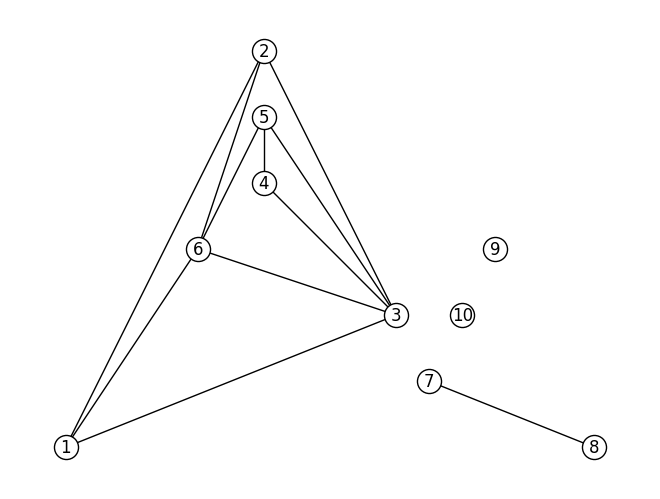

In [13]:
G = nx.Graph()
edges = [(1,2),(1,3),(2,3),(1,6),(2,6),(3,6),(3,4),(3,5),(4,5),(5,6),(7,8)]
G.add_nodes_from([1,2,3,4,5,6,7,8,9,10])
G.add_edges_from(edges)
plt.show()
nx.draw_planar(G,with_labels = True,node_color ='white',edge_color ='black',edgecolors ='black')

<h4>The number of nodes:<h4>

In [14]:
G.number_of_nodes()

10

<h4>The number of edges:<h4>

In [15]:
G.number_of_edges()

11

<h4>The number of connected components:<h4>

In [16]:
nx.number_connected_components(G)

4

In [17]:
nx.write_adjlist(G,'graph.txt')

<h3>Graph loading and visualization<h3>

In [19]:
g = nx.read_adjlist('graph.txt', nodetype= int)

In [20]:
g.nodes

NodeView((1, 2, 3, 6, 4, 5, 7, 8, 9, 10))

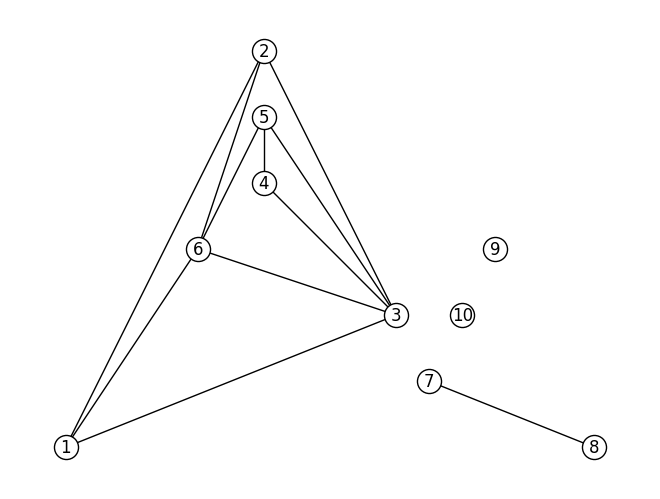

In [21]:
nx.draw_planar(G,with_labels= True, node_color='white',edge_color='black',edgecolors='black')
plt.savefig('task2.jpg')

<h3>Nodes positioning<h3>

In [42]:
pos= {1:(80,20),2:(20,20),3:(5,10),4:(40,60),5:(40,90),6:(60,70),7:(100,0),8:(0,0),9:(5,30),10:(85,40)}

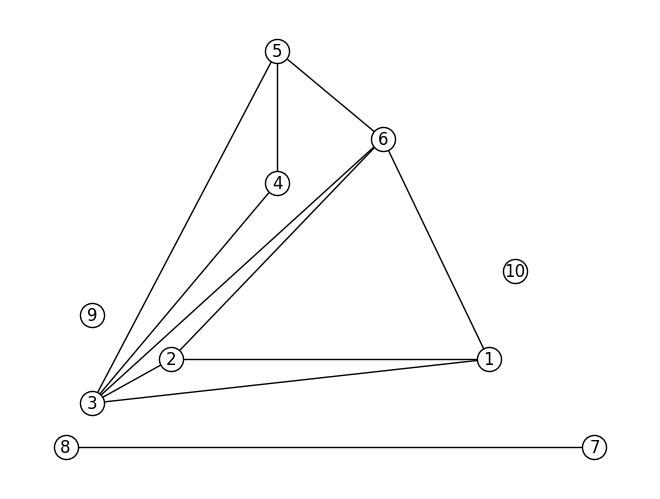

In [43]:
plt.show()
nx.draw(G,pos,with_labels= True, node_color='white',edge_color='black',edgecolors='black')
plt.savefig('task3.jpg')

<h3>Connected components<h3>

In [18]:
components = list(nx.connected_components(G))

for i, component_nodes in enumerate(components, 1):
    subgraph = G.subgraph(component_nodes)
    print(f"\nComponent {i}:")
    print(f" Number of nodes: {subgraph.number_of_nodes()}")
    print(f" Number of edges: {subgraph.number_of_edges()}")

    print(" Node degrees:")
    for node in subgraph.nodes():
        print(f" Node {node}: degree = {subgraph.degree[node]}")

    if nx.is_connected(subgraph) and subgraph.number_of_nodes() > 1:
        ecc = nx.eccentricity(subgraph)
        print(" Eccentricities:")
        for node, e in ecc.items():
            print(f" Node {node}: eccentricity = {e}")
        print(f" Radius: {nx.radius(subgraph)}")
        print(f" Diameter: {nx.diameter(subgraph)}")
    else:
        print(" Not enough connections to compute eccentricity, radius, and diameter.")



Component 1:
 Number of nodes: 6
 Number of edges: 10
 Node degrees:
 Node 1: degree = 3
 Node 2: degree = 3
 Node 3: degree = 5
 Node 4: degree = 2
 Node 5: degree = 3
 Node 6: degree = 4
 Eccentricities:
 Node 1: eccentricity = 2
 Node 2: eccentricity = 2
 Node 3: eccentricity = 1
 Node 4: eccentricity = 2
 Node 5: eccentricity = 2
 Node 6: eccentricity = 2
 Radius: 1
 Diameter: 2

Component 2:
 Number of nodes: 2
 Number of edges: 1
 Node degrees:
 Node 8: degree = 1
 Node 7: degree = 1
 Eccentricities:
 Node 8: eccentricity = 1
 Node 7: eccentricity = 1
 Radius: 1
 Diameter: 1

Component 3:
 Number of nodes: 1
 Number of edges: 0
 Node degrees:
 Node 9: degree = 0
 Not enough connections to compute eccentricity, radius, and diameter.

Component 4:
 Number of nodes: 1
 Number of edges: 0
 Node degrees:
 Node 10: degree = 0
 Not enough connections to compute eccentricity, radius, and diameter.


<h3>Diameters of nontrivial connected components<h3>

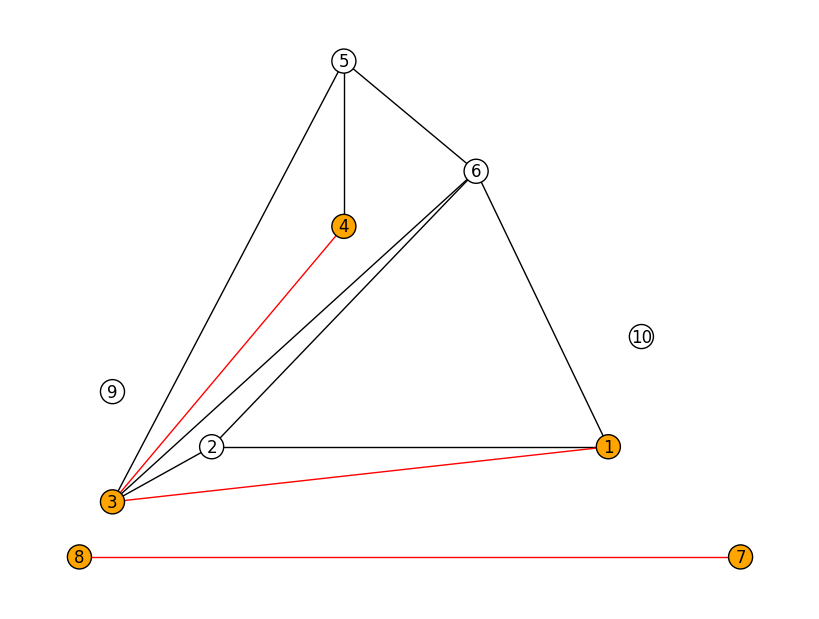

In [17]:
diameter_nodes = set()
diameter_edges = set()
components = list(nx.connected_components(G))


for comp in components:
    subgraph = G.subgraph(comp)
    if len(subgraph.nodes) > 1 and nx.is_connected(subgraph):
   
        max_len = -1
        diam_path = []
        for u in subgraph.nodes():
            for v in subgraph.nodes():
                if u != v:
                    try:
                        path = nx.shortest_path(subgraph, source=u, target=v)
                        if len(path)-1 > max_len:
                            max_len = len(path)-1
                            diam_path = path
                    except nx.NetworkXNoPath:
                        continue

      
        diameter_nodes.update(diam_path)
        diameter_edges.update([(diam_path[i], diam_path[i+1]) for i in range(len(diam_path)-1)])


node_colors = ['orange' if n in diameter_nodes else 'white' for n in G.nodes()]
edge_colors = ['red' if (u,v) in diameter_edges or (v,u) in diameter_edges else 'black' for u,v in G.edges()]


plt.figure(figsize=(8,6))
nx.draw(G, pos, with_labels=True, node_color=node_colors, edge_color=edge_colors, edgecolors='black')
plt.savefig('diameters_colored.jpg')  
plt.show()

<h3>Depth spanning forest<h3>

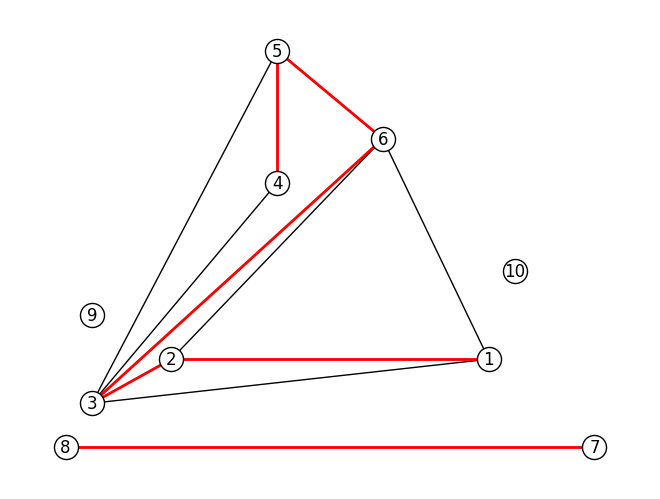

In [9]:
dfs_forest_edges = set()
for comp in nx.connected_components(G):
    subgraph = G.subgraph(comp)
    root = list(comp)[0]
    dfs_tree = nx.dfs_tree(subgraph, source=root)
    dfs_forest_edges.update(dfs_tree.edges())
nx.draw(G, pos, with_labels=True, node_color='white', edge_color='black', edgecolors='black')
nx.draw_networkx_edges(G, pos, edgelist=list(dfs_forest_edges), edge_color='red', width=2)
plt.title
plt.savefig("dfs_forest.png")
plt.show()